# 04 · Delta-hedged short straddle (Tier 3)

**Owner: Nahid** · initial GBM path simulation by Kevin Specht

Variance swaps aren't traded by most investors; options are. This notebook checks whether the premium in notebook 02 survives when you actually sell options and delta hedge them, and explains where the P&L comes from.

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data import load_daily, EPISODES, episode_mask
df = load_daily('../data/daily.csv')
df.tail()
from src import bs


## 0. Sanity check on simulated data (do this first)
Simulate 2,000 GBM paths (Lecture 4) with σ = 20%, 21 trading days. Sell a 30-day ATM straddle priced at σ = 20% and delta hedge daily.

Mean hedged P&L should be close to 0, with a small spread. Then price at 22% with true σ = 20%: the mean should be positive. If this doesn't work, the real backtest won't either.

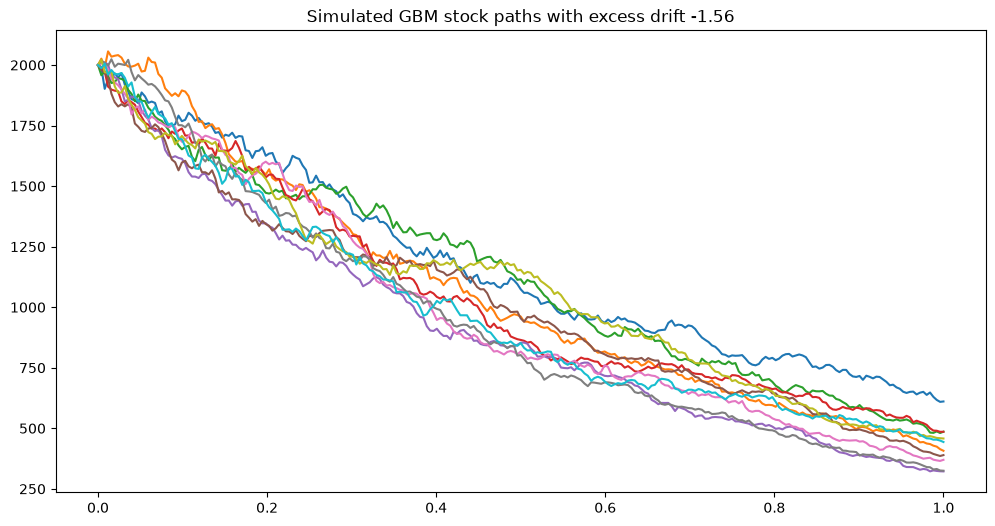

In [7]:
#review how to simulate geometric brownian motion stock paths with multiple steps

S0 = 2000
sigma = .20
t = 1
r = .039
mu = -1.56
n_steps = 252
dt = t/n_steps


n_sims = 10

noise = np.random.normal(size = (n_sims,n_steps))

log_returns = np.cumsum((mu+r - (0.5)*sigma**2)*dt + sigma*np.sqrt(dt)*noise, axis = 1)
log_returns = np.insert(log_returns,0,0,axis = 1)

stock_paths = S0*np.exp(log_returns)

times = np.linspace(0,t,n_steps+1)

plt.figure(figsize = (12,6))
for stock_path in stock_paths:
    plt.plot(times,stock_path)

plt.title(f'Simulated GBM stock paths with excess drift {mu}')
plt.show()


In [8]:
from src import bs
rng = np.random.default_rng(0)

def gbm_hedge_test(sigma_true, sigma_imp, n_paths=2000, n_days=21, S0=100.0):
    dt = 1 / 252
    T0 = n_days * dt
    z = rng.standard_normal((n_paths, n_days))
    S = S0 * np.exp(np.cumsum(-0.5 * sigma_true**2 * dt + sigma_true * np.sqrt(dt) * z, axis=1))
    S = np.hstack([np.full((n_paths, 1), S0), S])
    premium = bs.straddle_price(S0, S0, T0, 0.0, sigma_imp)
    hedge = np.zeros(n_paths)
    for i in range(n_days):
        delta = bs.straddle_delta(S[:, i], S0, T0 - i * dt, 0.0, sigma_imp)
        hedge += delta * (S[:, i + 1] - S[:, i])      # hold +delta shares against the short straddle
    pnl = premium - np.abs(S[:, -1] - S0) + hedge
    return 100 * pnl / S0                               # % of the stock price

for s_imp in [0.20, 0.22]:
    p = gbm_hedge_test(0.20, s_imp)
    print(f"priced at {s_imp:.0%}, true vol 20%: mean P&L = {p.mean():.3f}% of S "
          f"(± {1.96 * p.std() / np.sqrt(len(p)):.3f}), std = {p.std():.3f}%")
print(f"theory for 22%: vega x 2 vol pts = {bs.straddle_vega(100, 100, 21/252, 0, 0.20) * 0.02:.3f}% of S")

priced at 20%, true vol 20%: mean P&L = -0.024% of S (± 0.037), std = 0.844%
priced at 22%, true vol 20%: mean P&L = 0.472% of S (± 0.038), std = 0.873%
theory for 22%: vega x 2 vol pts = 0.460% of S


## 1. Backtest specification
- On the first trading day of each month (2005 onwards): sell 1 ATM straddle, K = S, T = 30/365, priced with Black–Scholes at σ_imp = VIX/100 − haircut. Use haircuts of 0, 1, 2 and 3 vol points, because VIX runs above ATM implied vol.
- Each day until expiry: mark the straddle at σ_imp (fixed at inception) with the remaining calendar time, and hold +delta of the index to hedge. Cash earns `rf`.
- At expiry (last trading day on or before inception + 30 days): pay |S_T − K|.
- P&L per contract = premium − payoff + hedge gains + interest. Report it as a percentage of S at inception.

In [9]:
px = df['spx_close']
rf = df['rf'].ffill().fillna(0.0)

def backtest_month(entry, sigma_imp):
    expiry = entry + pd.Timedelta(days=30)
    days = px.loc[entry:expiry].index
    S = px.loc[days].values
    K, r = S[0], rf.loc[entry]
    T = (expiry - days).days.values / 365                  # calendar time left
    dt = (days[1:] - days[:-1]).days.values / 365
    premium = bs.straddle_price(K, K, T[0], r, sigma_imp)
    vega0 = bs.straddle_vega(K, K, T[0], r, sigma_imp)
    delta = bs.straddle_delta(S[:-1], K, T[:-1], r, sigma_imp)
    gamma = bs.straddle_gamma(S[:-1], K, T[:-1], r, sigma_imp)
    dS = np.diff(S)
    payoff = abs(S[-1] - K)
    hedge = np.sum(delta * (dS - r * S[:-1] * dt))         # stock gains minus cost of borrowing
    interest = premium * r * dt.sum()                      # premium earns the risk-free rate
    pnl = premium - payoff + hedge + interest
    gamma_theta = np.sum(0.5 * gamma * S[:-1]**2 * (sigma_imp**2 * dt - (dS / S[:-1])**2))
    return {'entry': entry, 'K': K, 'sigma_imp': sigma_imp, 'premium': premium, 'payoff': payoff,
            'hedge': hedge, 'interest': interest, 'pnl': pnl,
            'pnl_net': pnl - 0.005 * vega0,                # option cost: 0.5 vol pt x vega
            'gamma_theta': gamma_theta}

entries = df.index.to_series().groupby(df.index.to_period('M')).first()
entries = entries[entries <= df.index[-1] - pd.Timedelta(days=31)]

rows = []
for h in [0, 1, 2, 3]:                                     # haircut in vol points
    for e in entries:
        rows.append(backtest_month(e, df.loc[e, 'vix'] / 100 - h / 100) | {'haircut': h})
res = pd.DataFrame(rows)
res['pnl_pct'] = 100 * res['pnl'] / res['K']
res['pnl_net_pct'] = 100 * res['pnl_net'] / res['K']
print(f"{res['entry'].nunique()} months, {res['entry'].min().date()} to {res['entry'].max().date()}")
display(res[res['haircut'] == 2].head().round(3))

262 months, 2005-01-03 to 2026-10-01


/var/folders/sv/2946ls810cv38vtwwnj1zhsr0000gn/T/ipykernel_56401/2467817896.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(res[res['haircut'] == 2].head().round(3))


,entry,K,sigma_imp,premium,payoff,hedge,interest,pnl,pnl_net,gamma_theta,haircut,pnl_pct,pnl_net_pct
524,2005-01-03,1202.08,0.121,33.233,8.89,-19.364,0.063,5.041,3.670,3.885,2,0.419,0.305
525,2005-02-01,1189.41,0.100,27.328,21.06,-8.429,0.055,-2.105,-3.461,-2.510,2,-0.177,-0.291
526,2005-03-01,1210.41,0.100,27.849,29.82,2.118,0.062,0.209,-1.170,0.577,2,0.017,-0.097
527,2005-04-01,1172.92,0.121,32.468,16.07,-24.119,0.068,-7.653,-8.990,-8.429,2,-0.652,-0.766
528,2005-05-02,1162.16,0.131,34.904,40.06,9.233,0.083,4.160,2.835,4.456,2,0.358,0.244


## 2. P&L attribution
For a short delta-hedged option, daily P&L ≈ ½ · Γ · S² · (σ_imp² · dt − r²), where r is that day's return. Sum it per month and compare with actual P&L; the difference is the discrete-hedging residual.

This explains *why* the strategy works: it earns theta when realized < implied, and loses on gamma when the market moves a lot.

corr(actual P&L, sum of ½ΓS²(σ_imp²·dt − r²)) = 0.978


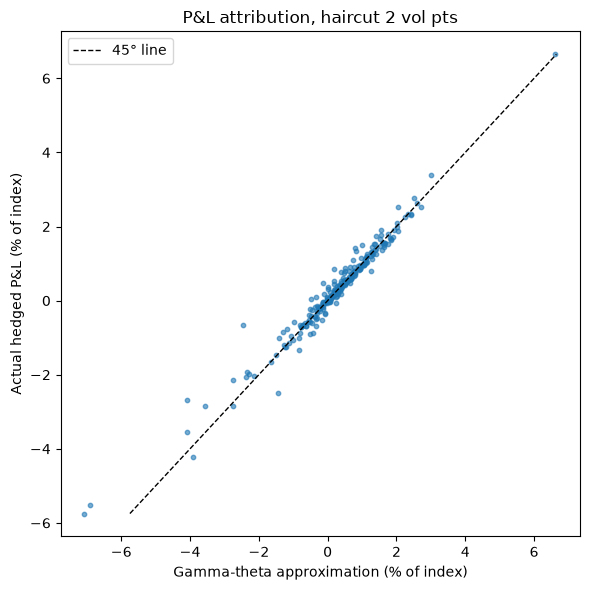

In [10]:
h2 = res[res['haircut'] == 2].set_index('entry')
c = h2['pnl'].corr(h2['gamma_theta'])
print(f"corr(actual P&L, sum of ½ΓS²(σ_imp²·dt − r²)) = {c:.3f}")
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(100 * h2['gamma_theta'] / h2['K'], h2['pnl_pct'], s=10, alpha=0.6)
lim = [h2['pnl_pct'].min(), h2['pnl_pct'].max()]
ax.plot(lim, lim, 'k--', lw=1, label='45° line')
ax.set_xlabel('Gamma-theta approximation (% of index)')
ax.set_ylabel('Actual hedged P&L (% of index)')
ax.set_title('P&L attribution, haircut 2 vol pts')
ax.legend()
plt.tight_layout()
plt.savefig('../docs/figures/fig4_attribution.png', dpi=150)
plt.show()


## 3. Results
- Distribution of monthly P&L for each haircut: mean, std, skew, 5% CVaR, worst month.
- Episode table (same `EPISODES` as notebook 02).
- Cumulative P&L chart with episodes shaded.

,mean %,median %,share positive,Sharpe (ann.),skew,5% CVaR %,worst month %,mean after option cost %
haircut,,,,,,,,
0,0.769,0.840,0.809,2.114,-0.913,-2.629,-5.830,0.655
1,0.543,0.621,0.763,1.514,-0.840,-2.805,-5.789,0.429
2,0.317,0.384,0.691,0.895,-0.771,-2.981,-5.747,0.203
3,0.092,0.195,0.592,0.261,-0.711,-3.159,-5.705,-0.022



Worst 5 months (haircut 2 vol pts), P&L in % of the index:
entry
2020-03-02   -5.75
2008-09-02   -5.51
2025-04-01   -4.23
2008-11-03   -3.55
2008-03-03   -2.85
Name: pnl_pct, dtype: float64


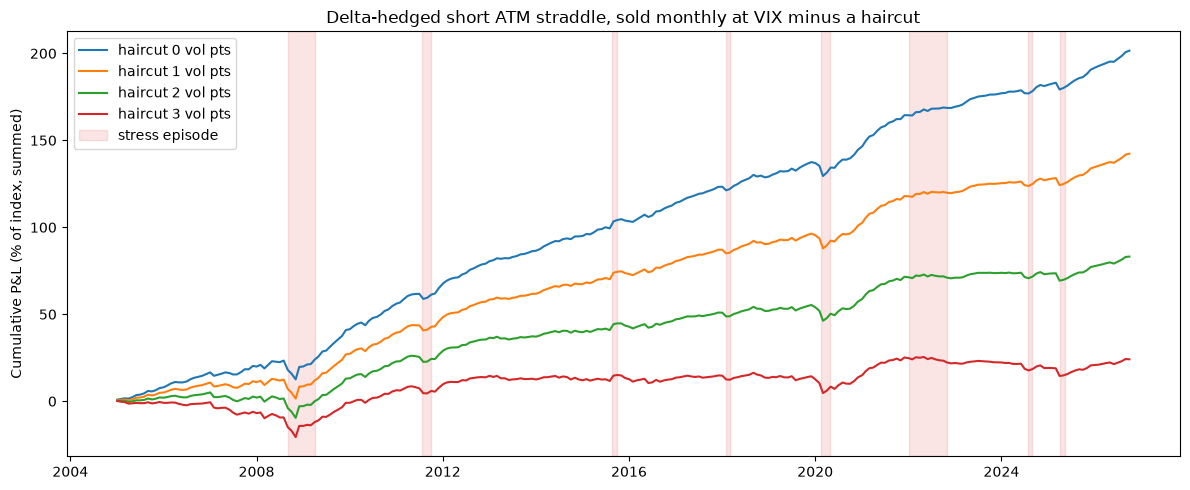

In [11]:
def summarize(x):
    k = max(1, int(np.ceil(0.05 * len(x))))
    return pd.Series({'mean %': x.mean(), 'median %': x.median(), 'share positive': (x > 0).mean(),
                      'Sharpe (ann.)': np.sqrt(12) * x.mean() / x.std(), 'skew': x.skew(),
                      '5% CVaR %': x.nsmallest(k).mean(), 'worst month %': x.min()})

table = res.groupby('haircut')['pnl_pct'].apply(summarize).unstack()
table['mean after option cost %'] = res.groupby('haircut')['pnl_net_pct'].mean()
display(table.round(3))
print('\nWorst 5 months (haircut 2 vol pts), P&L in % of the index:')
print(h2['pnl_pct'].nsmallest(5).round(2))

fig, ax = plt.subplots(figsize=(12, 5))
for h, g in res.groupby('haircut'):
    ax.plot(g['entry'], g['pnl_pct'].cumsum(), label=f'haircut {h} vol pts')
for i, (name, (s, e)) in enumerate(EPISODES.items()):
    ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color='tab:red', alpha=0.12, label='stress episode' if i == 0 else None)
ax.set_ylabel('Cumulative P&L (% of index, summed)')
ax.set_title('Delta-hedged short ATM straddle, sold monthly at VIX minus a haircut')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('../docs/figures/fig5_straddle_cumulative.png', dpi=150)
plt.show()

## 4. With the HAR signal
Once `signal` is in `daily.csv`: only sell in months where the signal is True at entry. Compare against always-sell, both overall and in the test period (2016 onwards).

In [12]:
on = df['signal'].reindex(h2.index).astype(bool)
cmp = {}
for label, idx in [('2007+', h2.index[h2.index >= '2007-01-01']), ('test 2016+', h2.index[h2.index >= '2016-01-01'])]:
    always = h2.loc[idx, 'pnl_pct']
    rule = always.where(on.loc[idx], 0.0)
    cmp[(label, 'always sell')] = summarize(always)
    cmp[(label, 'rule')] = summarize(rule)
    cmp[(label, 'always sell')]['months in market'] = 1.0
    cmp[(label, 'rule')]['months in market'] = on.loc[idx].mean()
display(pd.DataFrame(cmp).T.round(3))

mean %  median %  share positive  Sharpe (ann.)  \
2007+      always sell   0.331     0.448           0.693          0.894   
           rule          0.279     0.000           0.466          1.068   
test 2016+ always sell   0.305     0.458           0.700          0.908   
           rule          0.307     0.000           0.477          1.292   

                         skew  5% CVaR %  worst month %  months in market  
2007+      always sell -0.775     -3.179         -5.747             1.000  
           rule        -0.905     -1.935         -5.507             0.647  
test 2016+ always sell -1.652     -2.940         -5.747             1.000  
           rule         0.224     -1.501         -2.155             0.654

## 5. Takeaways for the executive summary
- **The premium survives in real options, but only if they are sold close to VIX.** A delta-hedged short ATM straddle sold monthly since 2005 earns +0.77% of the index per month priced at VIX and +0.32% at VIX − 2 vol points (Sharpe 0.9), falling to about zero at VIX − 3 after option costs. VIX includes out-of-the-money puts, so ATM options trade below it, and the realistic edge is thin.
- **We know where the P&L comes from.** Summing ½ΓS²(σ²dt − r²) each day explains the monthly P&L almost exactly (correlation 0.98): the trade earns theta when realized vol is below implied and loses on gamma in big moves. A GBM check confirms the hedge: priced at the true vol, the mean P&L is zero; priced 2 points too high, it earns vega × 2.
- **The signal cuts risk, not return.** Selling only when the HAR forecast premium is positive and the VIX curve is not inverted keeps the mean (0.31% per month in 2016+) while halving the 5% CVaR (−1.5% vs −2.9%) and the worst month (−2.2% vs −5.7%). This uses first-of-month entries only; notebook 03 shows that on an unlucky entry day the rule still takes the COVID loss.